In [ ]:
!python -m pip install lightcurvelynx


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.8/241.8 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 312.7/312.7 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 70.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 112.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 621.0/621.0 kB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 17.0 MB/s eta 

# download the repo with models

In [ ]:
!git clone https://github.com/fedhere/prestocolor/


Cloning into 'prestocolor'...
remote: Enumerating objects: 14730, done.
remote: Total 14730 (delta 0), reused 0 (delta 0), pack-reused 14730 (from 1)
Receiving objects: 100% (14730/14730), 379.00 MiB | 29.20 MiB/s, done.
Resolving deltas: 100% (1377/1377), done.
Updating files: 100% (13891/13891), done.


In [ ]:
import numpy as np
import glob
import os
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import RegularGridInterpolator
from lightcurvelynx.models.physical_model import SEDModel
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np

formatter=ScalarFormatter()
formatter.set_scientific(True)
formatter.set_powerlimits((-2,2))

# the Kasen infant SN models
these models describe the early optical emission of a SN Ia in a binary single degenerate scenario system. The whole carved by the companion in the ejecta enables flux to escape from the otherwise optically thick ejecta until the ejecta wraps around the companion closing the hole. Depending on the size and distance of the ejecta and on the viewing angle the amount of flux observed changes. Since the system is assumed to be in Roche lobe overflow, only one parameter is needed to describe the companion mass and distance jointly. Thus the model has two parameters:

- vieweing angle => 40 values between 12 and 167 degrees on a grid
- companion => 3 values:
  - a=5e11 km separation: M=2M_sum Main Sequence (MS) star
  - a=2e12 km separation: M=6M_sum MS star
  - a=2e13 km separation: M=1M_sum Red Giant (RG) star

The model produces the SED evolution (between 51 and 14852 AA) in the first 10 days since explosion, to be integrated within a spectral band.

Each companion will be modeled separately as a separate lynx model. the angle will be a model parameter in each

In [ ]:
angles = [167.1616, 157.6685, 151.0451, 145.5886,
          140.8052, 136.469, 132.4543, 128.6823,
          125.0997, 121.6683, 118.3595, 115.1508,
          112.0244, 108.9657, 105.9621, 103.0030,
          100.0787,  97.1808,  94.3013,  91.4326,
          88.5675,  85.6989,  82.8193,  79.9214,
          76.9972,  74.0380,  71.0345,  67.9757,
          64.8494,  61.6407,  58.3318,  54.9004,
          51.3179,  47.5459,  43.5312,  39.1950,
          34.4115,  28.9550,  22.3317,  12.8386]
wavelengths_grid = np.arange(51,14852,100)

times = np.arange(0.05,10,0.1)
rootdir = 'prestocolor/FastTrWP/models/companions/'
dists = {'a5e11':"2 M_sun MS star",
         'a2e12':"6 M_sun MS star",
         'a2e13':"1 M_sun RG star"}

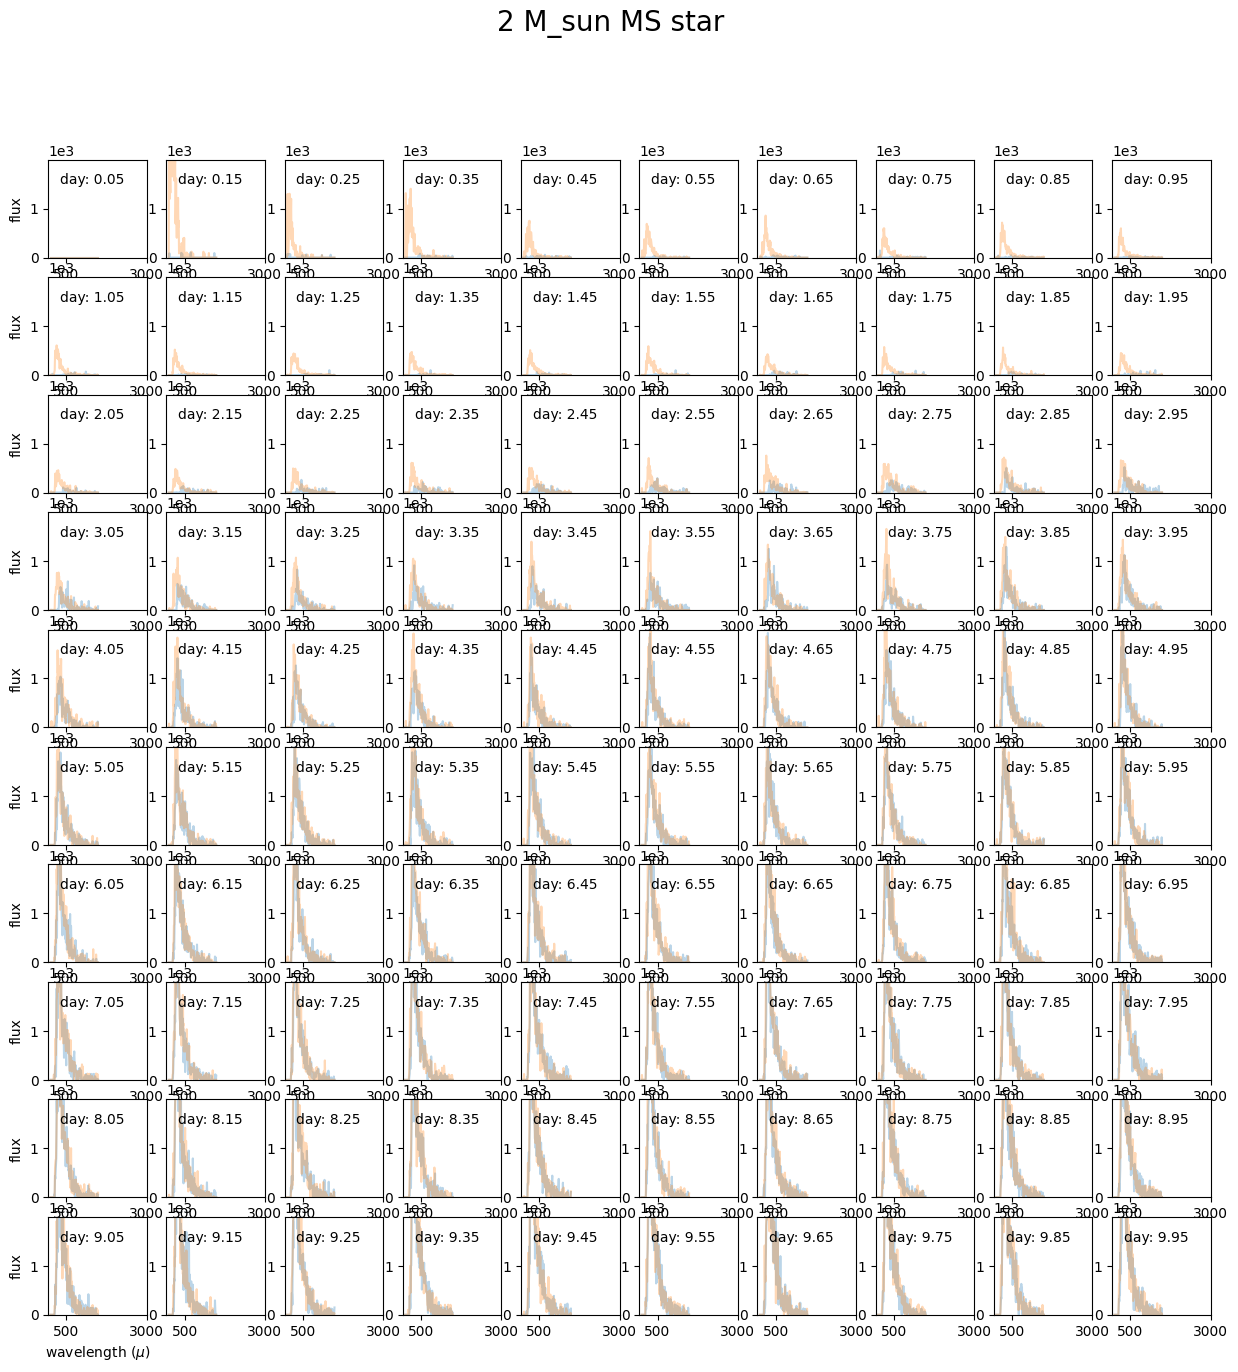

In [ ]:
dist = list(dists.keys())[0]
spdir = rootdir + '/companion_' + dist

fig1=plt.figure(figsize=(15,15))
fig1.suptitle(r"%s"%dists[dist], fontsize=20)
spectra = {dist:{}}

allspectra = spectra[dist]
# for each epoch read in a spectrum for each angle
for t,epoch in enumerate(np.arange(0.05,10,0.1)):
    allspectra[t]={'w': wavelengths_grid}
    allspectrafiles =  np.array(glob.glob(spdir + "/optical_t%06.2f_I3.spec.*"%epoch))

    for mu in angles:
        thisf = [ff.strip()  for ff in allspectrafiles if '%.4f'%mu in ff]
        allspectra[t][mu] = np.loadtxt(thisf[0], usecols=(1,))

    ax1=fig1.add_subplot(10, 10, t+1)
    ax1.text(300, 1500, "day: %.2f"%epoch)

    for k in allspectra[t]:
        if k == 'w':
            continue
        if k == 167.1616:
            ax1.plot(allspectra[t]['w'] * 0.1,
                     allspectra[t][k], alpha=0.3)

        if k == 12.8386:
            ax1.plot(allspectra[t]['w'] * 0.1,
                     allspectra[t][k], alpha=0.3)


    ax1.set_ylim(0, 2000)
    ax1.set_yticks([0, 1000])
    ax1.set_xticks([500, 3000])
    #ax1.xaxis.set_major_formatter(formatter)
    ax1.yaxis.set_major_formatter(formatter)


    if (t) % 10 == 0:
        ax1.set_ylabel("flux")

    if (t) / 10 == 9:
        ax1.set_xlabel(r"wavelength ($\mu$)")


# Build an interpolator for each model to pass to lclynx

In [ ]:
spectra_interpolator_3d = {}


# Prepare the 3D grid coordinates
epochs = np.array(times)
mus = np.array(angles)

# Ensure coordinates are sorted in ascending order for RegularGridInterpolator
sort_idx = np.argsort(mus)
mus_sorted = mus[sort_idx]


In [ ]:
for dist in list(dists.keys()):
  print("computing ", dist)
  spdir = rootdir + '/companion_' + dist

  fig1=plt.figure(figsize=(15,15))
  fig1.suptitle(r"%s"%dists[dist], fontsize=20)
  spectra = {dist:{}}

  allspectra = spectra[dist]
  # for each epoch read in a spectrum for each angle
  for t,epoch in enumerate(np.arange(0.05,10,0.1)):
      allspectra[t]={'w': wavelengths_grid}
      allspectrafiles =  np.array(glob.glob(spdir + "/optical_t%06.2f_I3.spec.*"%epoch))

      for mu in angles:
          thisf = [ff.strip()  for ff in allspectrafiles if '%.4f'%mu in ff]
          allspectra[t][mu] = np.loadtxt(thisf[0], usecols=(1,))

  spectra_data = np.zeros((len(times), len(angles), len(wavelengths_grid)))
  for t_idx, epoch in enumerate(times):
      for mu_idx, mu in enumerate(angles):
          # Map the original mu index to the sorted index's position
          sorted_mu_pos = np.where(mus_sorted == mu)[0][0]
          spectra_data[t_idx, sorted_mu_pos, :] = allspectra[t_idx][mu]

  # Build the 3D interpolator across (time, mu, wavelength)
  spectra_interpolator_3d[dist] = RegularGridInterpolator(
      (epochs, wavelengths_grid, mus_sorted),
      spectra_data.transpose(0,2,1),
      method='linear',
      bounds_error=False,
      fill_value=0.0
  )
  plt.show()

def get_interpolated_flux_3d(dist, t, w, mu):
      """
      Returns the linearly interpolated flux at a specific time 't',
      viewing angle 'mu', and wavelength 'w'.
      """
      return spectra_interpolator_3d[dist]((t, w, mu))

# Example of usage: querying a single continuous point
t_test = 2.35
mu_test = 90.0
w_test = 5000.0
interpolated_val = get_interpolated_flux_3d(list(dists.keys())[0], t_test, w_test, mu_test)
print(f"Interpolated flux at t={t_test}, w={w_test}, mu={mu_test}: {interpolated_val}")

computing  a5e11


<Figure size 1500x1500 with 0 Axes>

computing  a2e12


<Figure size 1500x1500 with 0 Axes>

computing  a2e13


<Figure size 1500x1500 with 0 Axes>

Interpolated flux at t=2.35, w=5000.0, mu=90.0: 97.16547655491956


# check interpolators graphically



In [ ]:


# Generate a dense 2D grid for time (t) and wavelength (w)
t_dense = np.linspace(epochs.min()+1, epochs.max(), 2000)
w_dense = np.linspace(wavelengths_grid.min(), wavelengths_grid.max(), 1000)

T_grid, W_grid = np.meshgrid(t_dense, w_dense)


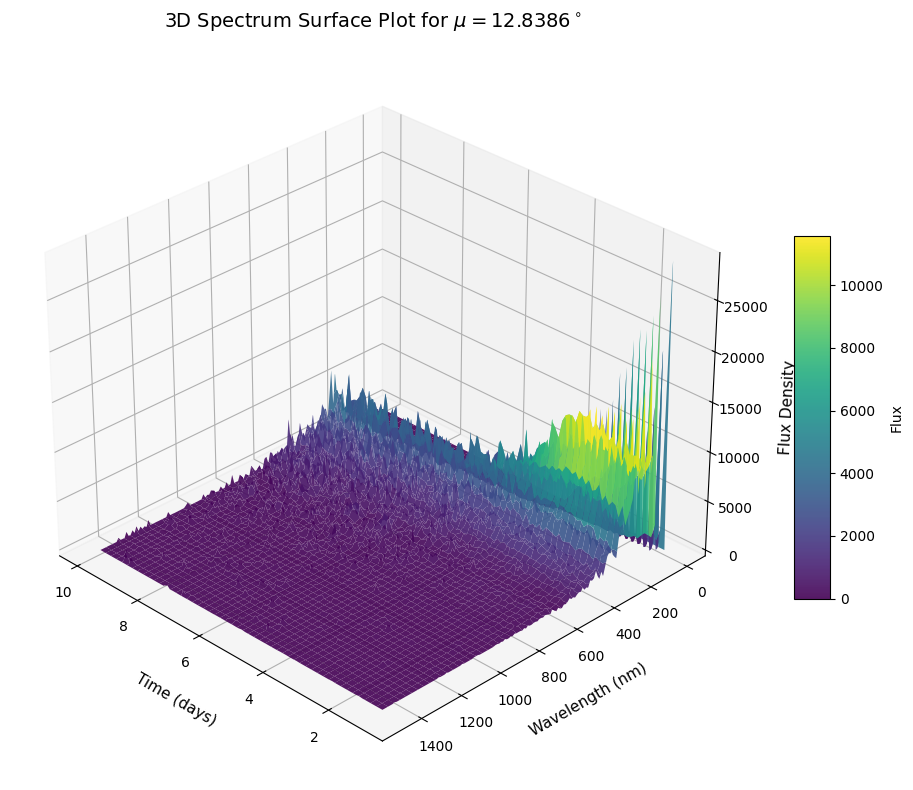

In [ ]:

# Fix mu at 90.0 degrees
fixed_mu = angles[-1]#100#angles[0]

# Evaluate the interpolator at each point on the grid
# Prepare input array of shape (N*M, 3) where each row is [t, mu, w]
query_pts = np.vstack([
    T_grid.ravel(),
    #np.full_like(T_grid.ravel(), fixed_mu),
    W_grid.ravel(),
    np.full_like(T_grid.ravel(), fixed_mu)
]).T

Z_flux_m1 = spectra_interpolator_3d[dist](query_pts).reshape(T_grid.shape)

# Create 3D Surface Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    T_grid,
    W_grid * 0.1,  # Convert to nm
    Z_flux_m1,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax.set_title(fr"3D Spectrum Surface Plot for $\mu = {fixed_mu}^\circ$", fontsize=14, pad=20)
ax.set_xlabel("Time (days)", fontsize=11, labelpad=10)
ax.set_ylabel("Wavelength (nm)", fontsize=11, labelpad=10)
ax.set_zlabel("Flux Density", fontsize=11, labelpad=10)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Flux')
ax.view_init(elev=30, azim=135) # Adjust viewing angle for better visualization

plt.tight_layout()
plt.show()

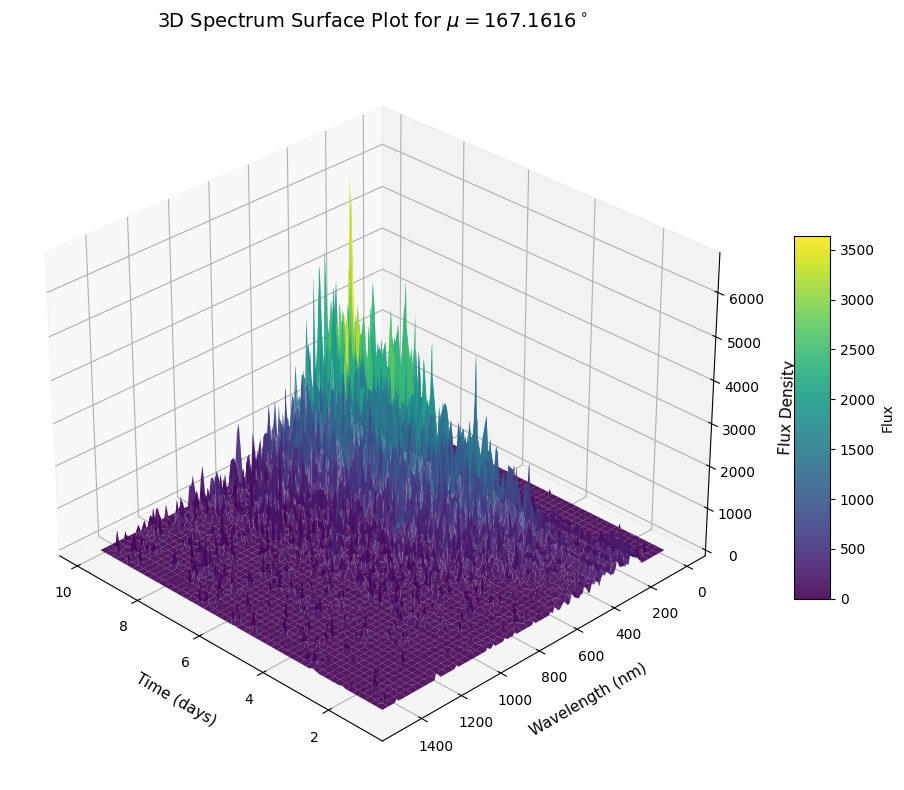

In [ ]:
# Fix mu at 90.0 degrees
fixed_mu = angles[0]#100#angles[0]


# Evaluate the interpolator at each point on the grid
# Prepare input array of shape (N*M, 3) where each row is [t, mu, w]
query_pts = np.vstack([
    T_grid.ravel(),
    #np.full_like(T_grid.ravel(), fixed_mu),
    W_grid.ravel(),
    np.full_like(T_grid.ravel(), fixed_mu)
]).T

Z_flux_0 = spectra_interpolator_3d[dist](query_pts).reshape(T_grid.shape)

# Create 3D Surface Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    T_grid,
    W_grid * 0.1,  # Convert to nm
    Z_flux_0,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax.set_title(fr"3D Spectrum Surface Plot for $\mu = {fixed_mu}^\circ$", fontsize=14, pad=20)
ax.set_xlabel("Time (days)", fontsize=11, labelpad=10)
ax.set_ylabel("Wavelength (nm)", fontsize=11, labelpad=10)
ax.set_zlabel("Flux Density", fontsize=11, labelpad=10)

fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='Flux')
ax.view_init(elev=30, azim=135) # Adjust viewing angle for better visualization

plt.tight_layout()
plt.show()

In [ ]:

wtest =  4451
select = query_pts[:,1] == w_dense[np.abs((w_dense-wtest)) == np.abs((w_dense-wtest)).min()][0]
select
Z_flux_0 = spectra_interpolator_3d["a2e13"](query_pts[select])

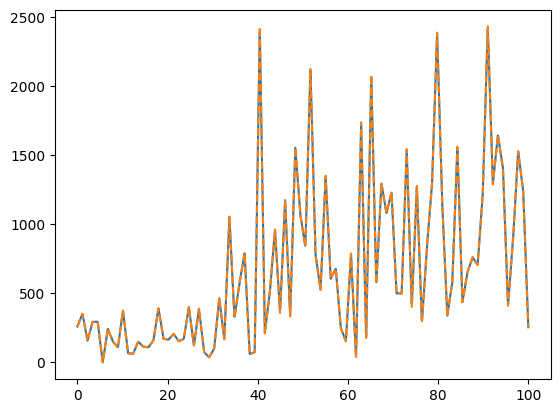

In [ ]:
plt.plot(np.linspace(0,100,select.sum()), spectra_interpolator_3d["a2e13"](query_pts[select]))
lcv = np.array([allspectra[t][167.1616][np.arange(51,14852,100)==wtest] for t,epoch
       in enumerate(np.arange(0.05,10,0.1))])
plt.plot(np.linspace(0,100,90), lcv[10:], '--')


# !!!! If the plots above are not overlapping there is a problem

# interpolators exist, put them in lightcurtve lynx

In [ ]:

class KasenIaCompanionModel(SEDModel):
    """A model that emits a 3D interpolated companion spectrum.

    Parameters
    ----------
    angle : `float`
        The viewing angle
    func : a dictionary of `RegularGridInterpolator`
        The 3D interpolator function.
    dist : the dictionary key to select the appropriate interpolator
        options: "a5e11", "a2e12", "a2e13"
    **kwargs : `dict`, optional
        Any additional keyword arguments.
    """

    def __init__(self, angle, func, dist, **kwargs):
        super().__init__(**kwargs)
        self.add_parameter(
            "angle",
            angle,
            description="The viewing angle",
        )

        # Store the interpolator as an instance attribute rather than an SED model parameter
        self.func = func
        self.dist = dist


    def compute_sed(self, times, wavelengths, graph_state, **kwargs):
        """Draw effect-free observations for this object.

        Parameters
        ----------
        times : `numpy.ndarray`
            A length T array of rest frame timestamps.
        wavelengths : `numpy.ndarray`, optional
            A length N array of wavelengths (in angstroms).
        graph_state : `GraphState`
            An object mapping graph parameters to their values.
        **kwargs : `dict`, optional
            Any additional keyword arguments.

        Returns
        -------
        flux_density : `numpy.ndarray`
            A length T x N matrix of SED values (in nJy).
        """
        params = self.get_local_params(graph_state)

        epochs = times - params["t0"]
        sed = np.zeros((len(epochs), len(wavelengths)))
        for i, t in enumerate(epochs):
            for j, w in enumerate(wavelengths):
                sed[i, j] = self.func[self.dist]((t, w, params["angle"]))
        return sed



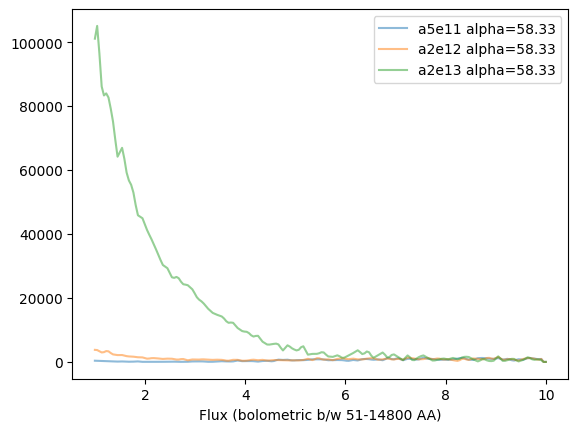

In [ ]:
a = -10
for dist in ["a5e11", "a2e12", "a2e13"]:
  model = KasenIaA2e13Model(angle=angles[a], t0=0.0,
                          func=spectra_interpolator_3d, dist=dist)

  times = np.linspace(1, 10.0, 200)
  wavelengths = np.linspace(0.0, 1500, 20)

  values = model.evaluate_sed(times, wavelengths)

  """
  plt.figure(figsize=(8, 5))
  for i,w in enumerate(wavelengths):
    plt.plot(times, values[:, i], linewidth=1, alpha=0.5)#, label="Model Flux at 100 Å")
  plt.xlabel("Time")
  plt.ylabel("Flux Density")
  plt.legend()
  plt.show()
  """
  plt.plot(times, values.sum(axis=1), alpha=0.5, label="%s alpha=%.2f"%(dist, angles[a]))
plt.legend()
plt.xlabel("Time")
plt.xlabel("Flux (bolometric b/w 51-14800 AA)");